# Telecom Customer Churn: Dataset Integrity, Train/Test Split, and Exploratory Data Analysis
**DADS 7275 — Milestone 1** · Author: Saketh Mandava

## 1. Introduction and objectives
This notebook is the project's single primary analysis notebook. Milestone 1 covers only:
dataset validation, a reproducible stratified train/test split, and **training-set-only** exploratory data analysis (EDA).
No models are trained, tuned, or evaluated here; those belong to later milestones.

**Framing.** The `Churn` field records customers who left within the last month, so this is a *retrospective
classification study*. Nothing here claims advance-prediction accuracy, causal effects, retention impact, or
deployment performance. Observed relationships are descriptive associations.

**Milestone 1 objectives**
1. Validate the raw Kaggle Telco Customer Churn CSV (structure, missing values, duplicates, categories, ranges).
2. Confirm `Churn` as the binary target and review predictors for redundancy and leakage risk.
3. Create one stratified 75/25 split (seed 42) and verify it.
4. Explore relationships with churn using the **training partition only**.

## 2. Dataset description
Source: Kaggle "Telco Customer Churn" (blastchar), stored unmodified at `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`.
One row per customer: `customerID`, demographics, phone/internet services, contract and billing fields,
`tenure` (months), `MonthlyCharges`, `TotalCharges`, and the target `Churn` (Yes/No).
There are no usage, complaint, or timestamp fields.

## 3. Libraries and configuration

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

SEED = 42
TEST_SIZE = 0.25
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Repository-relative paths: works from the project root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
RAW_PATH = ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert RAW_PATH.exists(), f"Raw CSV not found at {RAW_PATH}"
print("Project root:", ROOT.name)

Project root: telecom-churn-prediction


## 4. Dataset loading
The CSV is read as-is. We record its SHA-256 hash so any accidental modification of the raw file can be detected.
All derived columns are created on in-memory copies only; the file on disk is never written to.

In [2]:
RAW_SHA256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(RAW_PATH)
print("SHA-256 of raw file:", RAW_SHA256)
print("Shape:", raw.shape)
raw.head()

SHA-256 of raw file: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 5. Data integrity assessment
Each check below is computed from the loaded data; nothing is assumed from earlier assessments.

In [3]:
print(raw.dtypes.to_string())
print("\nExpected shape (7043, 21):", raw.shape == (7043, 21))
print("customerID unique:", raw["customerID"].is_unique)
print("Total NaN cells as read by pandas:", int(raw.isna().sum().sum()))

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str

Expected shape (7043, 21): True


customerID unique: True
Total NaN cells as read by pandas: 0


### 5.1 Blank strings and `TotalCharges`
`pandas` reports zero missing cells, but `TotalCharges` is read as text, which suggests hidden blank strings.

In [4]:
text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
blank_mask = raw["TotalCharges"].str.strip().eq("")
total_num = pd.to_numeric(raw["TotalCharges"], errors="coerce")
print("Blank-string TotalCharges:", int(blank_mask.sum()))
print("Non-numeric after coercion (NaN):", int(total_num.isna().sum()))
print("Coerced NaN rows are exactly the blank rows:", bool((total_num.isna() == blank_mask).all()))
other_blank = {c: int(raw[c].str.strip().eq("").sum()) for c in text_cols}
print("Blank strings per text column (non-zero only):", {k: v for k, v in other_blank.items() if v})
print()
print("tenure values among blank-TotalCharges rows:", raw.loc[blank_mask, "tenure"].unique())
print("Rows with tenure == 0 overall:", int((raw["tenure"] == 0).sum()))
print("Churn among blank rows:", raw.loc[blank_mask, "Churn"].value_counts().to_dict())
print("Contract among blank rows:", raw.loc[blank_mask, "Contract"].value_counts().to_dict())

Blank-string TotalCharges: 11
Non-numeric after coercion (NaN): 11
Coerced NaN rows are exactly the blank rows: True


Blank strings per text column (non-zero only): {'TotalCharges': 11}

tenure values among blank-TotalCharges rows: [0]
Rows with tenure == 0 overall: 11
Churn among blank rows: {'No': 11}
Contract among blank rows: {'Two year': 10, 'One year': 1}


**Finding.** There are exactly 11 blank `TotalCharges` values, and they coincide with the 11 customers whose
`tenure` is 0 (customers who had not yet completed a billing month). This is a structural, explainable pattern rather
than random corruption. In this notebook the blanks become `NaN` via numeric coercion on in-memory copies only.
They are **not imputed here**; imputation will be fit inside cross-validation pipelines in Milestone 2.
All 11 are non-churners. Setting them to 0 would be a plausible domain-based alternative to statistical imputation;
that choice is left to the Milestone 2 pipeline decision.

### 5.2 Duplicates and near-duplicates

In [5]:
feat_cols = [c for c in raw.columns if c != "customerID"]
print("Fully duplicated rows (including customerID):", int(raw.duplicated().sum()))
dup_extra = raw.duplicated(subset=feat_cols, keep="first")
dup_all = raw.duplicated(subset=feat_cols, keep=False)
print("Rows identical to an earlier row except customerID:", int(dup_extra.sum()))
print("Rows belonging to any such identical group:", int(dup_all.sum()))
print("Number of identical groups:", raw[dup_all].groupby(feat_cols, dropna=False).ngroups)
print("Churn within rows in groups:", raw.loc[dup_all, "Churn"].value_counts().to_dict())
print("Tenure of rows in groups (describe):")
print(raw.loc[dup_all, "tenure"].describe().round(1).to_string())

Fully duplicated rows (including customerID): 0
Rows identical to an earlier row except customerID: 22
Rows belonging to any such identical group: 42
Number of identical groups: 20


Churn within rows in groups: {'Yes': 24, 'No': 18}
Tenure of rows in groups (describe):
count    42.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0


**Finding.** No row is fully duplicated, and `customerID` is unique. 22 records match an earlier record on all 20
other columns, forming 20 identical groups (42 rows); every one of these rows has `tenure` = 1 month. Because the dataset has many
low-cardinality categorical columns and new customers tend to share default plans and prices, coincidental matches between distinct
customers are plausible (an interpretation, not a confirmed explanation). There is no evidence
that these are erroneous copies, so per `CLAUDE.md` they are **retained**. One consequence: identical feature rows can fall
in both train and test partitions, which could slightly flatter later test results. This is recorded as a risk.

### 5.3 Categorical values and numeric ranges

In [6]:
cat_cols = [c for c in text_cols if c not in ("customerID", "TotalCharges")]
for c in cat_cols:
    print(f"{c:18s}", raw[c].value_counts(dropna=False).to_dict())
print()
print(raw[["SeniorCitizen", "tenure", "MonthlyCharges"]].describe().round(2).to_string())
print("\nTotalCharges (valid values):")
print(total_num.describe().round(2).to_string())

gender             {'Male': 3555, 'Female': 3488}
Partner            {'No': 3641, 'Yes': 3402}
Dependents         {'No': 4933, 'Yes': 2110}
PhoneService       {'Yes': 6361, 'No': 682}
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling   {'Yes': 4171, 'No': 2872}
PaymentMethod      {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit 

In [7]:
# Logical consistency checks
svc = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_net = raw["InternetService"].eq("No")
print("InternetService == 'No':", int(no_net.sum()))
print("  ...of which all six add-on columns == 'No internet service':",
      int((raw.loc[no_net, svc] == "No internet service").all(axis=1).sum()))
print("  'No internet service' appearing where InternetService != 'No':",
      int((raw.loc[~no_net, svc] == "No internet service").sum().sum()))
nophone = raw["PhoneService"].eq("No")
print("PhoneService == 'No':", int(nophone.sum()), "| MultipleLines == 'No phone service':",
      int(raw["MultipleLines"].eq("No phone service").sum()),
      "| mismatches:", int((nophone != raw["MultipleLines"].eq("No phone service")).sum()))
print("SeniorCitizen values:", sorted(raw["SeniorCitizen"].unique()))
print("tenure range:", raw["tenure"].min(), "-", raw["tenure"].max())
print("MonthlyCharges <= 0:", int((raw["MonthlyCharges"] <= 0).sum()))
ratio = (total_num / (raw["tenure"] * raw["MonthlyCharges"])).replace([np.inf, -np.inf], np.nan)
print("TotalCharges / (tenure*MonthlyCharges): median %.2f, 5th-95th pct %.2f-%.2f" %
      (ratio.median(), ratio.quantile(.05), ratio.quantile(.95)))

InternetService == 'No': 1526
  ...of which all six add-on columns == 'No internet service': 1526
  'No internet service' appearing where InternetService != 'No': 0
PhoneService == 'No': 682 | MultipleLines == 'No phone service': 682 | mismatches: 0
SeniorCitizen values: [np.int64(0), np.int64(1)]
tenure range: 0 - 72
MonthlyCharges <= 0: 0
TotalCharges / (tenure*MonthlyCharges): median 1.00, 5th-95th pct 0.92-1.07


**Finding.** All categorical levels are valid and consistent. "No internet service" and "No phone service" are
*legitimate structural categories* determined by `InternetService` and `PhoneService`; they are not data errors.
They also mean the six add-on columns and `MultipleLines` are partly redundant with those parent fields.
`MonthlyCharges` and `tenure` are in plausible ranges. `TotalCharges` is approximately `tenure × MonthlyCharges`
(see ratio above; it also reflects price changes over time), so it is strongly related to `tenure`.
No invalid or inconsistent record needing removal was found.

## 6. Target and feature assessment
`Churn` is binary: **Yes** = the customer left within the last month (positive class, coded 1); **No** = the customer remained (coded 0).

In [8]:
y_full = raw["Churn"].map({"No": 0, "Yes": 1})
assert y_full.notna().all()
vc = raw["Churn"].value_counts()
print(pd.DataFrame({"count": vc, "percent": (vc / len(raw) * 100).round(2)}).to_string())
print("Imbalance ratio (No:Yes): %.2f : 1" % (vc["No"] / vc["Yes"]))

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54
Imbalance ratio (No:Yes): 2.77 : 1


In [9]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
binary_numeric = ["SeniorCitizen"]
categorical_features = [c for c in raw.columns if c not in ["customerID", "Churn"] + numeric_features + binary_numeric]
print("Identifier (excluded from modeling):", ["customerID"])
print("Target:", "Churn")
print("Numeric predictors:", numeric_features)
print("Binary-coded (0/1) predictor:", binary_numeric)
print(f"Categorical predictors ({len(categorical_features)}):", categorical_features)
print("Total candidate predictors:", len(numeric_features) + len(binary_numeric) + len(categorical_features))

Identifier (excluded from modeling): ['customerID']
Target: Churn
Numeric predictors: ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary-coded (0/1) predictor: ['SeniorCitizen']
Categorical predictors (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Total candidate predictors: 19


### Feature review notes
| Topic | Assessment |
|---|---|
| Identifier | `customerID` is unique per row and carries no behavioural information; it is excluded from all modeling. |
| Leakage | No column is a post-outcome field such as a cancellation date, reason, or retention offer, and none is derived from `Churn`. `tenure`/`TotalCharges` are measured up to the observation point; for churners they reflect the period before leaving, which is acceptable for a retrospective classification study but would need care in any forward-looking use. |
| Redundancy | `TotalCharges` ≈ `tenure × MonthlyCharges` (strongly correlated with `tenure`). Add-on service columns and `MultipleLines` embed `InternetService`/`PhoneService` through their "No internet/phone service" level. Correlated features share signal, which affects interpretation of importances, but **no predictor is removed** without approval. |
| Missing values | Only `TotalCharges` (11 blanks, all `tenure == 0`); to be handled by pipeline imputation in Milestone 2. |
| Preprocessing considerations | `TotalCharges` must be numeric; categorical predictors need one-hot encoding and numeric predictors scaling for logistic regression (Milestone 2, inside pipelines, fit on training folds only). `SeniorCitizen` is 0/1 while other binaries are Yes/No text. |
| Class imbalance | About 26.5% churners, so accuracy is not a useful headline metric; F1/ROC-AUC and class weighting are appropriate later. |

## 7. Stratified train/test split
One split, created once: 75% training / 25% testing, `random_state=42`, stratified on `Churn`, using
`train_test_split`. The original DataFrame index (row position) and `customerID` are preserved so membership
can be audited. No preprocessing has been fitted before this point.

In [10]:
# Work on a copy; TotalCharges coerced to numeric (blanks -> NaN). No imputation, encoding, or scaling.
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn_bin"] = df["Churn"].map({"No": 0, "Yes": 1})

train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, random_state=SEED, stratify=df["Churn"]
)
print("Train:", train_df.shape, "| Test:", test_df.shape)

Train: (5282, 22) | Test: (1761, 22)


In [11]:
print("Train / test rows:", len(train_df), "/", len(test_df), "| total", len(train_df) + len(test_df))
prop = pd.DataFrame({
    "full": df["Churn"].value_counts(normalize=True),
    "train": train_df["Churn"].value_counts(normalize=True),
    "test": test_df["Churn"].value_counts(normalize=True),
}).mul(100).round(2)
print("\nChurn class proportions (%):"); print(prop.to_string())
print("\nCounts of Churn=Yes: train", int(train_df['Churn_bin'].sum()), "| test", int(test_df['Churn_bin'].sum()))

assert set(train_df.index).isdisjoint(test_df.index), "row index overlap"
assert set(train_df["customerID"]).isdisjoint(test_df["customerID"]), "customerID overlap"
assert set(train_df.index) | set(test_df.index) == set(df.index), "partitions do not cover the data"
print("\nNo row-index or customerID overlap; partitions together cover all rows: OK")

tr2, te2 = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df["Churn"])
assert list(tr2.index) == list(train_df.index) and list(te2.index) == list(test_df.index)
print("Repeated split is identical (same rows, same order): OK")

print("NaN TotalCharges counts: train", int(train_df['TotalCharges'].isna().sum()), "| test", int(test_df['TotalCharges'].isna().sum()))
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == RAW_SHA256
print("Raw CSV hash unchanged since loading: OK")

Train / test rows: 5282 / 1761 | total 7043

Churn class proportions (%):
        full  train   test
Churn                     
No     73.46  73.46  73.48
Yes    26.54  26.54  26.52

Counts of Churn=Yes: train 1402 | test 467

No row-index or customerID overlap; partitions together cover all rows: OK
Repeated split is identical (same rows, same order): OK
NaN TotalCharges counts: train 8 | test 3
Raw CSV hash unchanged since loading: OK


**Decision recorded.** The split is held in memory and regenerated deterministically from `SEED = 42`; no split files are written.
Later milestones should reuse this exact call (same data frame, `test_size`, seed, and `stratify`) and can re-verify membership via the
`customerID`/index checks above. The test partition is not touched again in this notebook: the following sections use only `train_df`.

**Leakage note.** The split happens before any statistic is computed from features. Only the test set's size, class balance and
missing-`TotalCharges` count (for stratification/integrity verification) are reported above; test feature distributions and
their relationships with churn are intentionally not inspected.

## 8. Training-set exploratory data analysis
**From here on, only `train_df` is used.** `test_df` is not referenced. Churn rate in any category is
*churned customers in the category ÷ all training customers in that category*.

In [12]:
train = train_df.copy()
BASE = train["Churn_bin"].mean()
COLORS = {"No": "#4C78A8", "Yes": "#E4572E"}

def churn_table(col, order=None):
    g = train.groupby(col, observed=True)["Churn_bin"].agg(customers="size", churned="sum", churn_rate="mean")
    g["churn_rate_%"] = (g["churn_rate"] * 100).round(1)
    g = g.drop(columns="churn_rate")
    if order is not None:
        g = g.reindex(order)
    return g

def rate_barplot(col, order=None, title=None, ax=None, rotate=0):
    t = churn_table(col, order)
    ax = ax or plt.gca()
    bars = ax.bar(t.index.astype(str), t["churn_rate_%"], color="#E4572E")
    for b, n in zip(bars, t["customers"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%\n(n={n:,})",
                ha="center", va="bottom", fontsize=9)
    ax.axhline(BASE * 100, color="black", ls="--", lw=1, label=f"Training overall: {BASE*100:.1f}%")
    ax.set_ylabel("Churn rate (% of customers in category)")
    ax.set_xlabel(col)
    ax.set_title(title or f"Churn rate by {col}")
    ax.set_ylim(0, max(t["churn_rate_%"].max() * 1.35, BASE * 130))
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(axis="x", visible=False)
    if rotate: plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right")
    return t

### A. Target distribution

       customers  percent
Churn                    
No          3880    73.46
Yes         1402    26.54
Imbalance ratio (No:Yes): 2.77 : 1


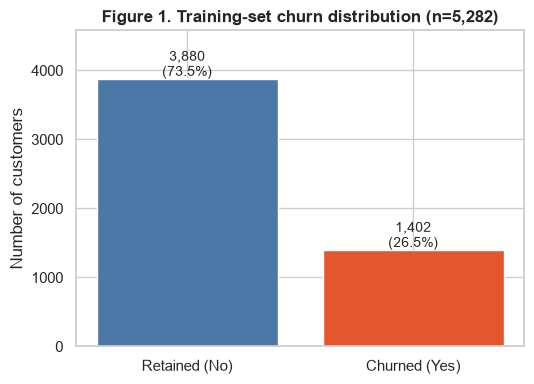

In [13]:
vc = train["Churn"].value_counts()
tab = pd.DataFrame({"customers": vc, "percent": (vc / len(train) * 100).round(2)})
print(tab.to_string())
print("Imbalance ratio (No:Yes): %.2f : 1" % (vc["No"] / vc["Yes"]))

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["Retained (No)", "Churned (Yes)"], [vc["No"], vc["Yes"]], color=[COLORS["No"], COLORS["Yes"]])
for b, v in zip(bars, [vc["No"], vc["Yes"]]):
    ax.text(b.get_x() + b.get_width()/2, v + 40, f"{v:,}\n({v/len(train)*100:.1f}%)", ha="center", fontsize=10)
ax.set_ylabel("Number of customers"); ax.set_title("Figure 1. Training-set churn distribution (n=%s)" % f"{len(train):,}")
ax.set_ylim(0, vc.max() * 1.18)
plt.tight_layout(); plt.show()

About one in four training customers churned (roughly a 2.8 : 1 class ratio). A classifier that always predicts "No"
would score about 73% accuracy while finding no churners, so accuracy alone is misleading; later milestones use
F1 on the churn class, ROC-AUC, class weighting, and a majority-class baseline.

### B. Customer tenure

        count  mean   std  min   25%   50%   75%   max
Churn                                                 
No     3880.0  37.4  24.2  0.0  15.0  37.0  61.0  72.0
Yes    1402.0  18.3  19.9  1.0   2.0  10.0  29.8  72.0



              customers  churned  churn_rate_%
tenure_group                                  
0-6                1117      583          52.2
7-12                535      203          37.9
13-24               752      205          27.3
25-48              1207      242          20.0
49-72              1671      169          10.1


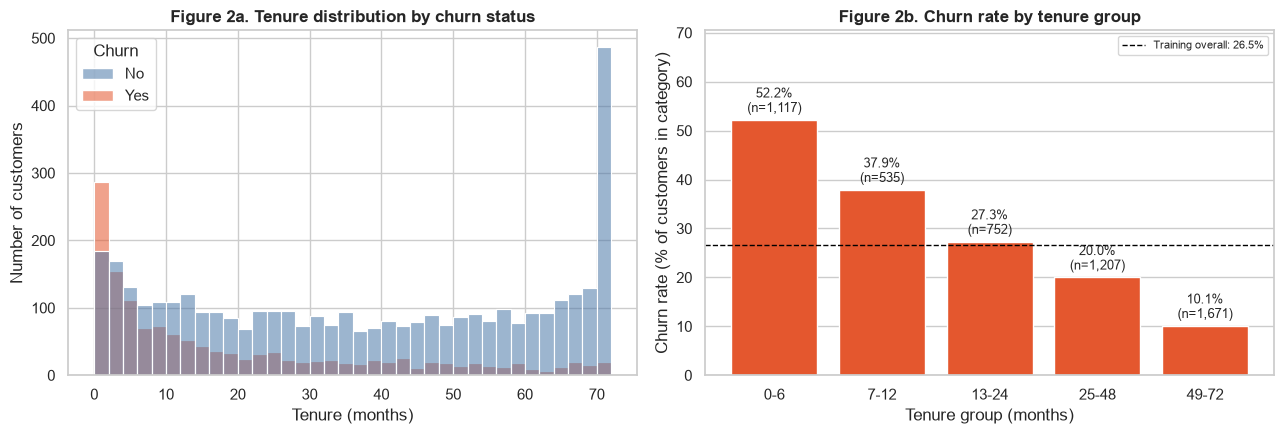

In [14]:
print(train.groupby("Churn")["tenure"].describe().round(1).to_string())
labels = ["0-6", "7-12", "13-24", "25-48", "49-72"]
train["tenure_group"] = pd.cut(train["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=labels)
print(); print(churn_table("tenure_group", labels).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=train, x="tenure", hue="Churn", bins=36, multiple="layer", stat="count", alpha=0.55,
             palette=COLORS, ax=axes[0])
axes[0].set_xlabel("Tenure (months)"); axes[0].set_ylabel("Number of customers")
axes[0].set_title("Figure 2a. Tenure distribution by churn status")
rate_barplot("tenure_group", labels, "Figure 2b. Churn rate by tenure group", ax=axes[1])
axes[1].set_xlabel("Tenure group (months)")
plt.tight_layout(); plt.show()

Churned customers have much shorter tenures, and the churn rate falls steadily with tenure group (see table).
Customers leave at all tenure levels, so tenure is a descriptive correlate, not a deterministic rule; and because the
data is a snapshot, short tenure among churners may partly reflect when customers joined relative to the snapshot.

### C. Contract type

                customers  churned  churn_rate_%  share_of_customers_%
Contract                                                              
Month-to-month       2907     1241          42.7                  55.0
One year             1107      123          11.1                  21.0
Two year             1268       38           3.0                  24.0


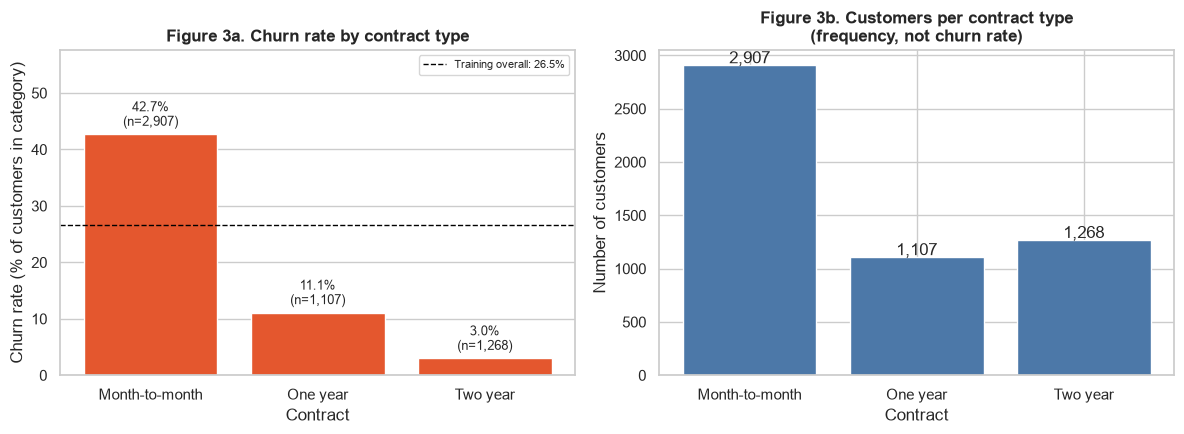

Mean tenure (months) by contract:
Contract
Month-to-month    18.0
One year          42.2
Two year          56.7


In [15]:
ct_order = ["Month-to-month", "One year", "Two year"]
ct = churn_table("Contract", ct_order)
ct["share_of_customers_%"] = (ct["customers"] / len(train) * 100).round(1)
print(ct.to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
rate_barplot("Contract", ct_order, "Figure 3a. Churn rate by contract type", ax=axes[0])
axes[1].bar(ct.index, ct["customers"], color="#4C78A8")
for i, v in enumerate(ct["customers"]): axes[1].text(i, v + 20, f"{v:,}", ha="center")
axes[1].set_title("Figure 3b. Customers per contract type\n(frequency, not churn rate)")
axes[1].set_ylabel("Number of customers"); axes[1].set_xlabel("Contract")
plt.tight_layout(); plt.show()
print("Mean tenure (months) by contract:"); print(train.groupby("Contract")["tenure"].mean().reindex(ct_order).round(1).to_string())

Month-to-month customers churn at a far higher rate (about 43%) than one-year (about 11%) or two-year (3%) customers. Contract type is also tied to
tenure (longer contracts have longer average tenures, printed above), so the two relationships overlap and cannot be separated by
these descriptive tables alone.

### D. Monthly charges

        count   mean    std    min    25%   50%    75%     max
Churn                                                         
No     3880.0  61.28  31.18  18.40  25.15  64.4  88.16  118.75
Yes    1402.0  74.76  24.64  18.85  56.25  79.9  94.40  118.35

               customers  churned  churn_rate_%
monthly_group                                  
<=35                1305      138          10.6
35-55                674      192          28.5
55-75                948      254          26.8
75-95               1380      500          36.2
>95                  975      318          32.6


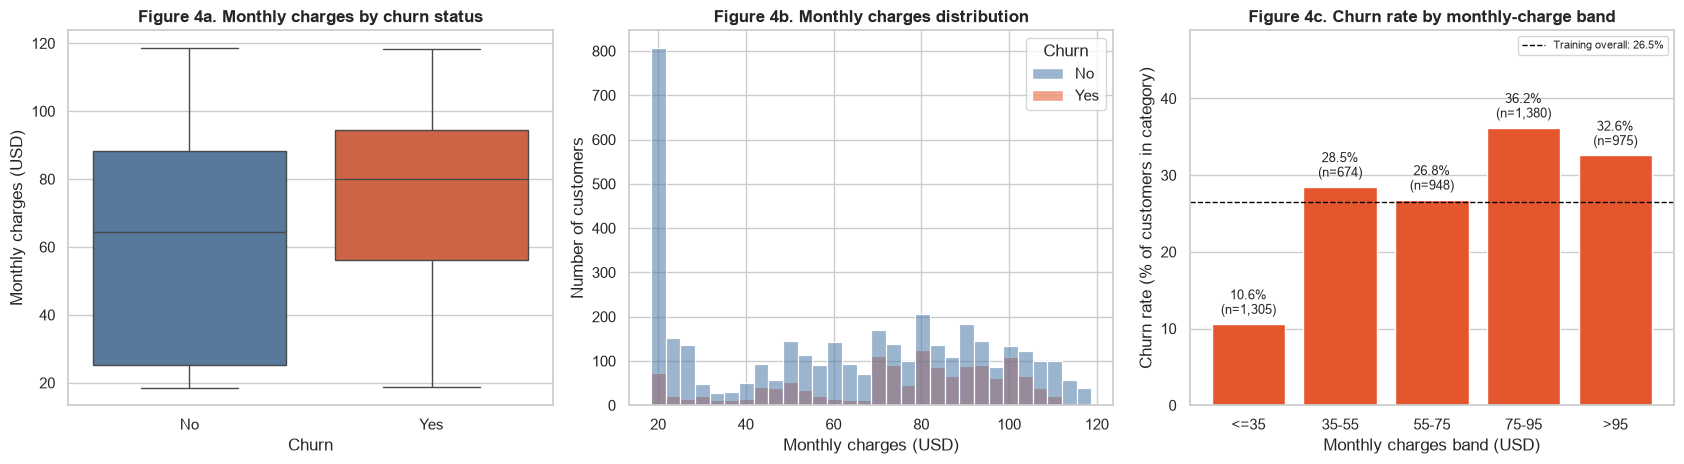

In [16]:
print(train.groupby("Churn")["MonthlyCharges"].describe().round(2).to_string())
mg_labels = ["<=35", "35-55", "55-75", "75-95", ">95"]
train["monthly_group"] = pd.cut(train["MonthlyCharges"], bins=[0, 35, 55, 75, 95, 120], labels=mg_labels)
print(); print(churn_table("monthly_group", mg_labels).to_string())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.boxplot(data=train, x="Churn", y="MonthlyCharges", hue="Churn", palette=COLORS, legend=False, ax=axes[0])
axes[0].set_title("Figure 4a. Monthly charges by churn status"); axes[0].set_ylabel("Monthly charges (USD)")
sns.histplot(data=train, x="MonthlyCharges", hue="Churn", bins=30, palette=COLORS, alpha=0.55, ax=axes[1])
axes[1].set_title("Figure 4b. Monthly charges distribution"); axes[1].set_xlabel("Monthly charges (USD)"); axes[1].set_ylabel("Number of customers")
rate_barplot("monthly_group", mg_labels, "Figure 4c. Churn rate by monthly-charge band", ax=axes[2])
axes[2].set_xlabel("Monthly charges band (USD)")
plt.tight_layout(); plt.show()

Churners have higher monthly charges on average (table above); the relationship is not monotonic across bands (see Figure 4c).
Monthly charges depend on which services a customer has (notably fiber optic), so this overlaps with the service analysis below.

### E. Total charges

Training rows with missing TotalCharges: 8
  tenure values: [0] | Churn counts: {'No': 8}

        count    mean     std   min    25%     50%     75%     max
Churn                                                             
No     3872.0  2560.9  2346.3  18.9  565.9  1678.0  4266.6  8672.4
Yes    1402.0  1562.8  1926.6  18.8  139.1   690.4  2368.9  8684.8

Spearman correlations with TotalCharges (valid rows): tenure 0.893 | MonthlyCharges 0.641


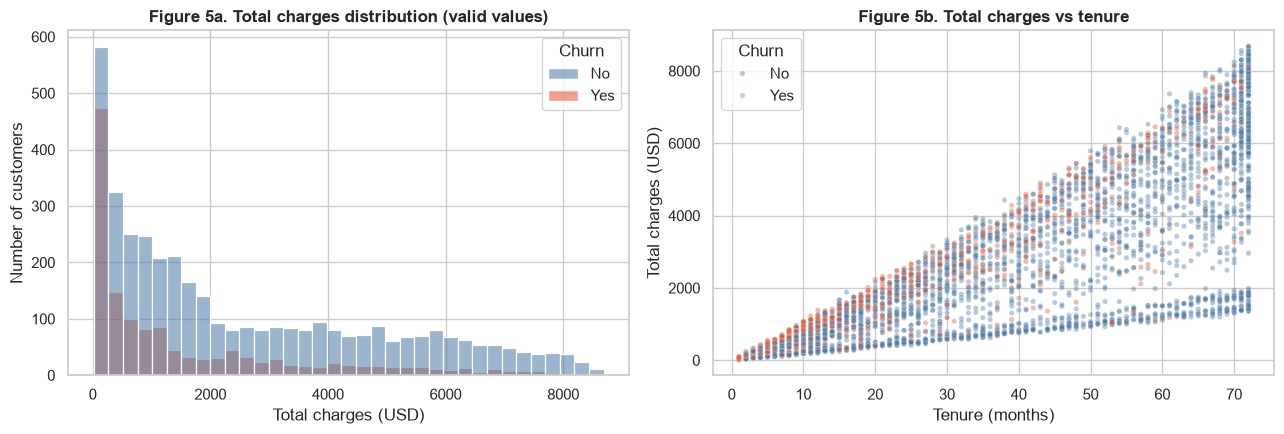

In [17]:
na_rows = train[train["TotalCharges"].isna()]
print("Training rows with missing TotalCharges:", len(na_rows))
print("  tenure values:", na_rows["tenure"].unique().tolist(), "| Churn counts:", na_rows["Churn"].value_counts().to_dict())
valid = train.dropna(subset=["TotalCharges"])
print(); print(valid.groupby("Churn")["TotalCharges"].describe().round(1).to_string())
print("\nSpearman correlations with TotalCharges (valid rows): tenure %.3f | MonthlyCharges %.3f" %
      (valid["TotalCharges"].corr(valid["tenure"], method="spearman"),
       valid["TotalCharges"].corr(valid["MonthlyCharges"], method="spearman")))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=valid, x="TotalCharges", hue="Churn", bins=35, palette=COLORS, alpha=0.55, ax=axes[0])
axes[0].set_title("Figure 5a. Total charges distribution (valid values)"); axes[0].set_xlabel("Total charges (USD)"); axes[0].set_ylabel("Number of customers")
sns.scatterplot(data=valid.sample(frac=1, random_state=SEED), x="tenure", y="TotalCharges", hue="Churn",
                palette=COLORS, alpha=0.4, s=14, ax=axes[1])
axes[1].set_title("Figure 5b. Total charges vs tenure"); axes[1].set_xlabel("Tenure (months)"); axes[1].set_ylabel("Total charges (USD)")
plt.tight_layout(); plt.show()

Missing `TotalCharges` occurs only for `tenure == 0` customers (all non-churners). Among valid values, total charges are right-skewed
and rise roughly with tenure; churners have lower totals, which is expected given their shorter tenures. Total charges therefore
likely add limited information beyond tenure and monthly charges.

### F. Service subscriptions

                 customers  churned  churn_rate_%
InternetService                                  
DSL                   1816      343          18.9
Fiber optic           2323      976          42.0
No                    1143       83           7.3

              customers  churned  churn_rate_%
PhoneService                                  
Yes                4752     1277          26.9
No                  530      125          23.6

Churn rate (%) by add-on service level:
level              Yes    No  No internet service
service                                          
DeviceProtection  22.7  39.1                  7.3
OnlineBackup      21.5  40.1                  7.3
OnlineSecurity    14.5  42.0                  7.3
StreamingMovies   30.1  33.6                  7.3
StreamingTV       30.3  33.4                  7.3
TechSupport       15.1  41.9                  7.3


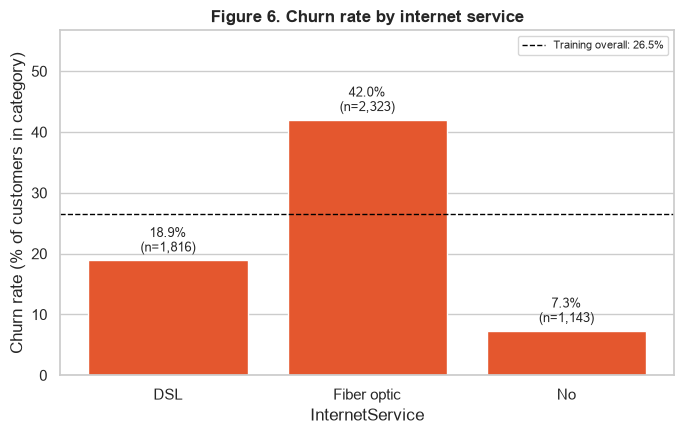

In [18]:
net_order = ["DSL", "Fiber optic", "No"]
print(churn_table("InternetService", net_order).to_string())
print(); print(churn_table("PhoneService", ["Yes", "No"]).to_string())
svc_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
rows = []
for c in svc_cols:
    for lvl in ["Yes", "No", "No internet service"]:
        s = train[train[c] == lvl]
        rows.append({"service": c, "level": lvl, "customers": len(s), "churn_rate_%": round(s["Churn_bin"].mean() * 100, 1)})
svc_tab = pd.DataFrame(rows).pivot(index="service", columns="level", values="churn_rate_%")[["Yes", "No", "No internet service"]]
print(); print("Churn rate (%) by add-on service level:"); print(svc_tab.to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
rate_barplot("InternetService", net_order, "Figure 6. Churn rate by internet service", ax=ax)
plt.tight_layout(); plt.show()

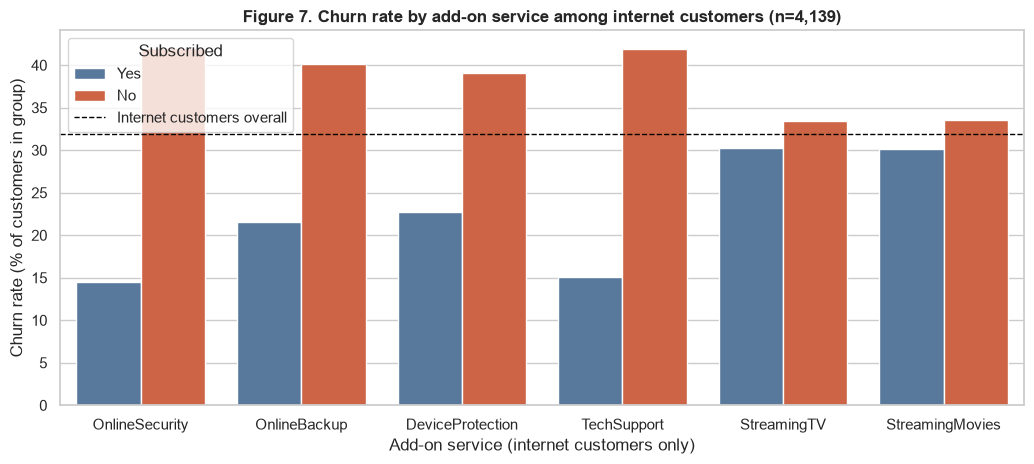

                  rate             n        
Subscribed          No   Yes      No     Yes
Service                                     
DeviceProtection  39.1  22.7  2305.0  1834.0
OnlineBackup      40.1  21.5  2300.0  1839.0
OnlineSecurity    42.0  14.5  2618.0  1521.0
StreamingMovies   33.6  30.1  2077.0  2062.0
StreamingTV       33.4  30.3  2076.0  2063.0
TechSupport       41.9  15.1  2585.0  1554.0


In [19]:
inet = train[train["InternetService"] != "No"]
plot_rows = []
for c in svc_cols:
    for lvl in ["Yes", "No"]:
        s = inet[inet[c] == lvl]
        plot_rows.append({"Service": c, "Subscribed": lvl, "rate": s["Churn_bin"].mean() * 100, "n": len(s)})
pr = pd.DataFrame(plot_rows)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.barplot(data=pr, x="Service", y="rate", hue="Subscribed", palette={"Yes": "#4C78A8", "No": "#E4572E"}, ax=ax)
ax.axhline(inet["Churn_bin"].mean() * 100, color="black", ls="--", lw=1, label="Internet customers overall")
ax.set_ylabel("Churn rate (% of customers in group)"); ax.set_xlabel("Add-on service (internet customers only)")
ax.set_title(f"Figure 7. Churn rate by add-on service among internet customers (n={len(inet):,})")
ax.legend(title="Subscribed"); plt.tight_layout(); plt.show()
print(pr.assign(rate=pr.rate.round(1)).pivot(index="Service", columns="Subscribed", values=["rate", "n"]).to_string())

Compare the internet-service rates above: fiber-optic customers churn at a markedly higher rate than DSL customers, and customers with no
internet service churn least. Among internet customers, those without online security or tech support churn more than those with them,
while the streaming services show a smaller gap (Figure 7 and tables). Phone service differences are small.
These are associations: fiber customers differ in price, tenure, and contract mix, so these patterns are confounded and no service-related
causal effect can be claimed.

### G. Billing and payment characteristics

                           customers  churned  churn_rate_%
PaymentMethod                                              
Electronic check                1772      804          45.4
Mailed check                    1207      238          19.7
Bank transfer (automatic)       1171      191          16.3
Credit card (automatic)         1132      169          14.9

                  customers  churned  churn_rate_%
PaperlessBilling                                  
Yes                    3132     1063          33.9
No                     2150      339          15.8


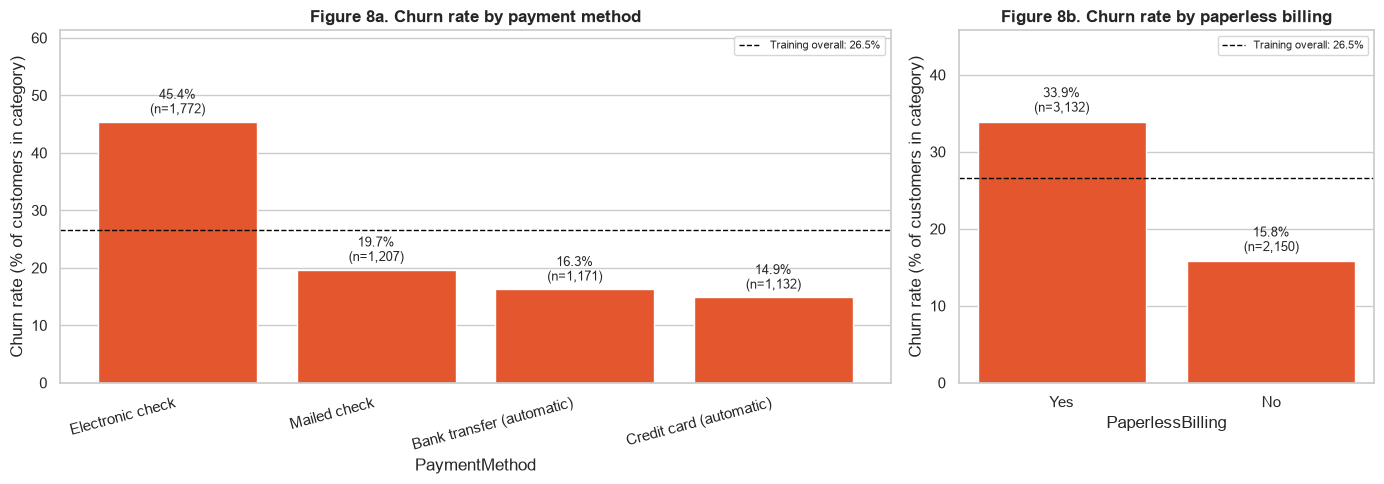

In [20]:
pm_order = train["PaymentMethod"].value_counts().index.tolist()
print(churn_table("PaymentMethod", pm_order).to_string())
print(); print(churn_table("PaperlessBilling", ["Yes", "No"]).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
rate_barplot("PaymentMethod", pm_order, "Figure 8a. Churn rate by payment method", ax=axes[0], rotate=15)
rate_barplot("PaperlessBilling", ["Yes", "No"], "Figure 8b. Churn rate by paperless billing", ax=axes[1])
plt.tight_layout(); plt.show()

Electronic-check customers churn at a much higher rate than customers on automatic payment methods, and paperless-billing customers churn
more than paper-billing customers (tables above). Payment method is likely entangled with contract type, tenure, and customer segment.

### H. Demographic and household characteristics

               customers  churned  churn_rate_%
SeniorCitizen                                  
0                   4426     1048          23.7
1                    856      354          41.4

         customers  churned  churn_rate_%
Partner                                  
No            2749      900          32.7
Yes           2533      502          19.8

            customers  churned  churn_rate_%
Dependents                                  
No               3713     1163          31.3
Yes              1569      239          15.2

        customers  churned  churn_rate_%
gender                                  
Female       2625      699          26.6
Male         2657      703          26.5



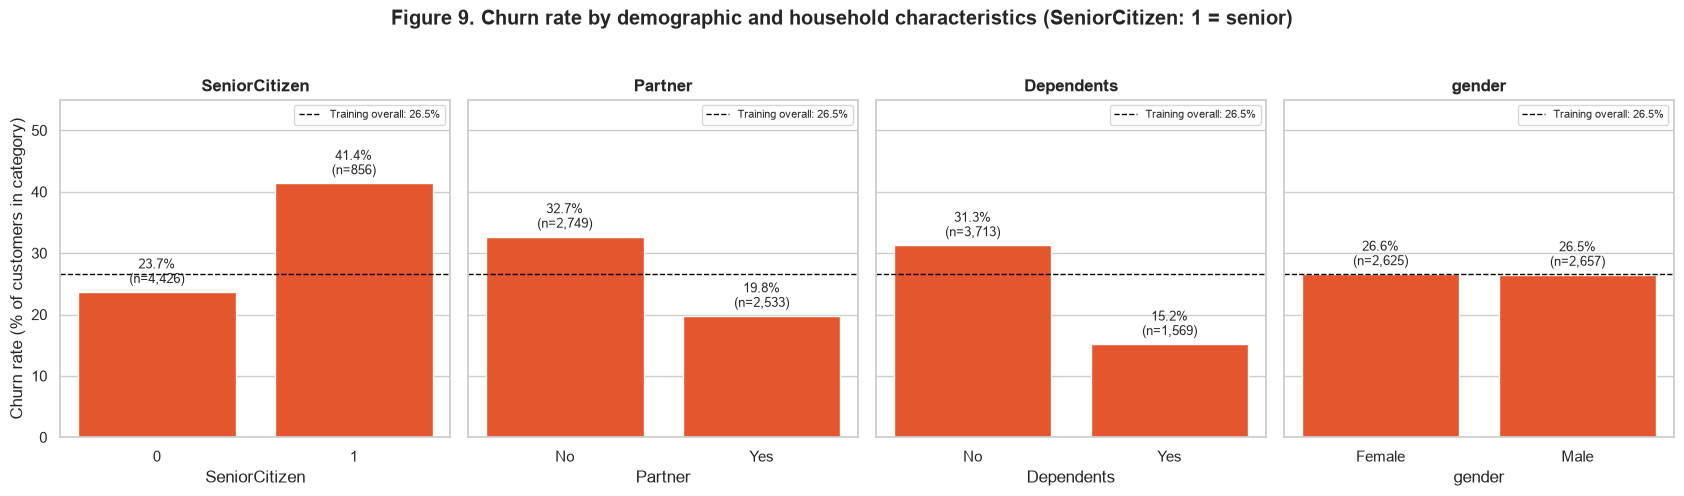

In [21]:
demo_cols = ["SeniorCitizen", "Partner", "Dependents", "gender"]
for c in demo_cols:
    print(churn_table(c).to_string()); print()
fig, axes = plt.subplots(1, 4, figsize=(17, 4.8), sharey=True)
for ax, c in zip(axes, demo_cols):
    order = [0, 1] if c == "SeniorCitizen" else sorted(train[c].unique())
    rate_barplot(c, order, c, ax=ax)
    ax.set_ylabel("Churn rate (% of customers in category)" if ax is axes[0] else "")
axes[0].set_ylim(0, 55)  # shared y-axis: common limit so no bar or label is clipped
fig.suptitle("Figure 9. Churn rate by demographic and household characteristics (SeniorCitizen: 1 = senior)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

Senior citizens, customers without a partner, and customers without dependents churn more often (tables above); the gender difference is negligible.
Household variables overlap with each other and with tenure/contract, so these are descriptive associations only.

### Numeric-feature correlation (training set)

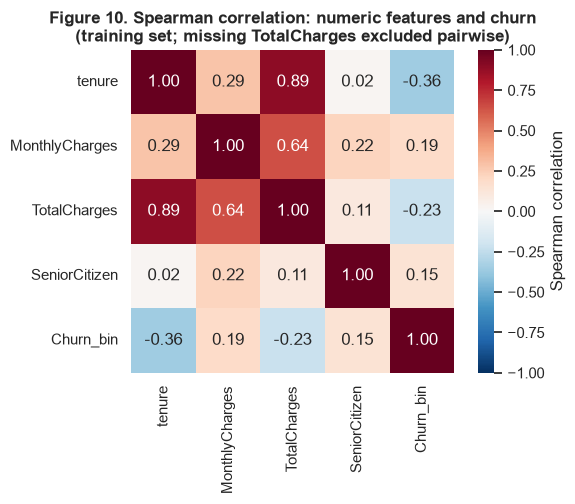

In [22]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn_bin"]
corr = train[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Figure 10. Spearman correlation: numeric features and churn\n(training set; missing TotalCharges excluded pairwise)")
plt.tight_layout(); plt.show()

`tenure` and `TotalCharges` are strongly correlated (the redundancy flagged earlier). Correlation here is a descriptive summary and is not a measure of model importance.

## 9. Preliminary observations

In [23]:
def rate(mask): return train.loc[mask, "Churn_bin"].mean() * 100
groups = {
    "Month-to-month contract": train.Contract == "Month-to-month",
    "Two-year contract": train.Contract == "Two year",
    "Tenure 0-6 months": train.tenure <= 6,
    "Tenure 49-72 months": train.tenure > 48,
    "Fiber optic internet": train.InternetService == "Fiber optic",
    "DSL internet": train.InternetService == "DSL",
    "No internet service": train.InternetService == "No",
    "Electronic check": train.PaymentMethod == "Electronic check",
    "Automatic payment (bank/card)": train.PaymentMethod.str.contains("automatic"),
    "Internet customers, no TechSupport": (train.InternetService != "No") & (train.TechSupport == "No"),
    "Internet customers, with TechSupport": train.TechSupport == "Yes",
    "Internet customers, no OnlineSecurity": (train.InternetService != "No") & (train.OnlineSecurity == "No"),
    "Internet customers, with OnlineSecurity": train.OnlineSecurity == "Yes",
    "Senior citizen": train.SeniorCitizen == 1,
    "Non-senior": train.SeniorCitizen == 0,
}
summary = pd.DataFrame([(k, round(rate(m), 1), int(m.sum())) for k, m in groups.items()],
                       columns=["Group", "Churn rate %", "Customers"])
print("Training overall churn rate: %.1f%%" % (BASE * 100))
summary

Training overall churn rate: 26.5%


,Group,Churn rate %,Customers
0,Month-to-month contract,42.7,2907
1,Two-year contract,3.0,1268
2,Tenure 0-6 months,52.2,1117
3,Tenure 49-72 months,10.1,1671
4,Fiber optic internet,42.0,2323
5,DSL internet,18.9,1816
6,No internet service,7.3,1143
7,Electronic check,45.4,1772
8,Automatic payment (bank/card),15.6,2303
9,"Internet customers, no TechSupport",41.9,2585


### Summary of descriptive findings (training set only)
Exact figures are in the tables above (notably the summary table directly preceding this text); figure references are in parentheses.

1. **Contract type (Fig. 3a).** Month-to-month customers churned at 42.7% versus 3.0% for two-year customers.
   *Why it may matter:* a strongly separating variable for later classifiers. *Limitations:* overlaps with tenure and payment method; descriptive only.
2. **Tenure (Figs. 2a, 2b).** Churners have much shorter tenures; churn is highest in the earliest tenure groups.
   *May matter:* likely informative in any model. *Limitations:* snapshot data cannot show timing of risk; tenure and `TotalCharges` are strongly related.
3. **Internet service and support add-ons (Figs. 6, 7).** Fiber-optic customers churn most; internet customers without online security or tech support churn more than those with them.
   *May matter:* service configuration may add information beyond demographics. *Limitations:* confounded with price, tenure and contract; "No internet service" levels are structurally tied to `InternetService`.
4. **Monthly charges (Figs. 4a–4c).** Churners have higher monthly charges on average; the pattern across bands is non-monotonic.
   *May matter:* non-linear models may capture this. *Limitations:* charges are driven by the service bundle.
5. **Payment and billing (Figs. 8a, 8b).** Electronic check and paperless billing are associated with higher churn. *Limitations:* likely proxies for other customer characteristics.
6. **Demographics (Fig. 9).** Seniors and customers without partner/dependents churn more; gender shows essentially no difference. *Limitations:* overlapping variables.
7. **Class imbalance (Fig. 1).** About a quarter of training customers churned; this affects metric choice and may call for class weighting.

None of these statements implies causation, and none is a model-based importance claim; predictive value must be assessed in later milestones using cross-validation.

## 10. Limitations and next steps
**Limitations of Milestone 1**
- Retrospective snapshot data; no timestamps, usage, or complaint information; churn is a one-month window.
- The 22 near-duplicate records are retained and may appear in both partitions.
- `TotalCharges` is highly related to `tenure × MonthlyCharges`; add-on and phone columns are partly redundant by construction.
- EDA used descriptive statistics without significance testing or multivariate adjustment; associations may be confounded.
- Tenure/charge groupings were chosen as round-number cutoffs for exploration only; they are not model features.
- No predictive performance has been measured.

**Next (Milestone 2, requires explicit authorization):** build scikit-learn pipelines (imputation of `TotalCharges`, one-hot encoding, scaling),
the majority-class dummy baseline, and five-fold stratified cross-validation (`StratifiedKFold(5, shuffle=True, random_state=42)`) of the four models on the training set.

In [24]:
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == RAW_SHA256
print("Raw data unchanged. No models were trained in this notebook. Milestone 1 complete.")

Raw data unchanged. No models were trained in this notebook. Milestone 1 complete.
